# Fashion Dataset Cleaning, Preprocessing & Multimodal Catalog Preparation

This notebook performs end-to-end data auditing, cleaning, and preprocessing for the **Fashion Product Retrieval with CLIP** project.
It processes raw metadata from `dataset/styles.csv` and cross-verifies all product images across `dataset/images` and `archive/images`.

### Pipeline Overview
1. **CSV Ingestion & Audit:** Parse `styles.csv` with strict validation, repairing unquoted comma anomalies in product names and quarantining malformed rows.
2. **Metadata Cleaning & Identifier Validation:** Normalize Unicode/whitespace, validate product IDs as positive integers, audit years, handle missing categories, and isolate duplicate/conflicting records.
3. **Dual Image Repository Audit:** Verify image decodability, RGB conversion, EXIF orientation, dimensions, and SHA-256 byte-hashes across all image files in parallel.
4. **Cross-Modal Catalog Merging & Alignment:** Inner join clean metadata with verified readable images, resolve duplicates, and flag byte-identical image groups.
5. **Feature Engineering for CLIP Search:** Construct unified search text representations and relative asset paths.
6. **Exploratory Data Analysis (EDA):** Visualize category distributions, image dimensions, aspect ratios, and duplicate groups.
7. **Development Sample & Preview Gallery:** Generate a deterministic 500-sample dataset and visual preview gallery.
8. **Integrity Assertions & Artifact Exports:** Rigorously verify mathematical consistency and export cleaned datasets and audit logs to `artifacts/data_preparation/`.

Run all cells sequentially. Original source data is preserved unmodified.

In [1]:
import csv
import hashlib
import io
import json
from pathlib import Path
import platform
import re
import unicodedata
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import pandas as pd
import PIL
from PIL import Image, ImageOps
from IPython.display import display

# Workspace root detection
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dataset/styles.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the project folder or a subfolder.')

OUTPUT = ROOT / 'artifacts/data_preparation'
OUTPUT.mkdir(parents=True, exist_ok=True)

SEED = 42
CSV_PATH = ROOT / 'dataset/styles.csv'
IMAGE_DIRS = [ROOT / 'dataset/images', ROOT / 'archive/images']
EXPECTED = ['id', 'gender', 'masterCategory', 'subCategory', 'articleType',
            'baseColour', 'season', 'year', 'usage', 'productDisplayName']

print(f'Project Root : {ROOT}')
print(f'Output Path  : {OUTPUT}')
print(f'Source CSV   : {CSV_PATH}')
print(f'Image Dirs   : {[d.relative_to(ROOT).as_posix() for d in IMAGE_DIRS]}')

Project Root : D:\data science and analysis\data analysis with python\deep learning\week3
Output Path  : D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation
Source CSV   : D:\data science and analysis\data analysis with python\deep learning\week3\dataset\styles.csv
Image Dirs   : ['dataset/images', 'archive/images']


## 1. Read and Audit the Raw CSV

The raw `dataset/styles.csv` contains occasional unquoted commas inside the `productDisplayName` field (fields > 10).
We use strict standard CSV parsing:
- If a row has more than 10 fields, we preserve the first 9 structured columns and recombine the remaining fields into `productDisplayName`.
- If a row has fewer than 10 fields, it is quarantined into `csv_audit`.
- Physical line numbers (`source_line`) are tracked for full provenance and auditability.

In [2]:
records, csv_issues = [], []
source_rows = 0

with CSV_PATH.open(encoding='utf-8-sig', newline='') as handle:
    reader = csv.reader(handle, strict=True)
    header = next(reader)
    assert header == EXPECTED, f'Unexpected schema: {header}'
    while True:
        source_line = reader.line_num + 1
        try:
            row = next(reader)
        except StopIteration:
            break
        source_rows += 1
        if len(row) != len(header):
            action = 'repaired_final_field' if len(row) > len(header) else 'quarantined_short_row'
            csv_issues.append({
                'source_line': source_line,
                'field_count': len(row),
                'action': action,
                'original_fields': json.dumps(row, ensure_ascii=False)
            })
            if len(row) < len(header):
                continue
            row = row[:9] + [','.join(row[9:])]
        records.append(dict(zip(header, row), source_line=source_line))

raw = pd.DataFrame(records)
csv_audit = pd.DataFrame(csv_issues, columns=['source_line', 'field_count', 'action', 'original_fields'])

print(f'Source records scanned : {source_rows:,}')
print(f'Parsed records retained: {len(raw):,}')
print(f'CSV formatting issues  : {len(csv_audit):,} ({csv_audit["action"].value_counts().to_dict()})')

display(csv_audit.head(10))
display(raw.head())

Source records scanned : 44,446
Parsed records retained: 44,446
CSV formatting issues  : 22 ({'repaired_final_field': 22})


,source_line,field_count,action,original_fields
0,6044,11,repaired_final_field,"[""44065"", ""Men"", ""Personal Care"", ""Fragrance"",..."
1,6569,11,repaired_final_field,"[""3413"", ""Men"", ""Apparel"", ""Topwear"", ""Tshirts..."
2,7399,11,repaired_final_field,"[""23101"", ""Men"", ""Accessories"", ""Accessories"",..."
3,7939,11,repaired_final_field,"[""23108"", ""Men"", ""Accessories"", ""Accessories"",..."
4,9026,11,repaired_final_field,"[""4854"", ""Unisex"", ""Footwear"", ""Shoes"", ""Casua..."
5,10264,11,repaired_final_field,"[""23109"", ""Men"", ""Accessories"", ""Accessories"",..."
6,10427,11,repaired_final_field,"[""23100"", ""Men"", ""Accessories"", ""Accessories"",..."
7,10905,11,repaired_final_field,"[""23107"", ""Men"", ""Accessories"", ""Accessories"",..."
8,11373,11,repaired_final_field,"[""59768"", ""Women"", ""Accessories"", ""Jewellery"",..."
9,11945,11,repaired_final_field,"[""23114"", ""Men"", ""Accessories"", ""Accessories"",..."


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,source_line
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Turtle Check Men Navy Blue Shirt,2
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012,Casual,Peter England Men Party Blue Jeans,3
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016,Casual,Titan Women Silver Watch,4
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011,Casual,Manchester United Men Solid Black Track Pants,5
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012,Casual,Puma Men Grey T-shirt,6


## 2. Clean Metadata and Validate Identifiers

In this stage:
- Text is normalized using Unicode NFKC and excess whitespace is stripped; blank entries are converted to `pd.NA`.
- Product `id` must be a valid positive integer string (`[0-9]{1,18}`); invalid IDs are quarantined.
- Duplicate metadata records are audited: exact duplicates retain their first occurrence; conflicting metadata for the same ID is quarantined.
- The `year` field is checked for plausible four-digit Gregorian years (1900–2100) and cast to nullable `Int64`.
- Missing category fields are flagged with explicit boolean tracking columns (`{col}_was_missing`) and imputed with `'Unknown'`.
- Missing product titles are imputed with `'Unnamed product ' + id`.

In [3]:
def clean_text(value):
    if pd.isna(value):
        return pd.NA
    value = re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(value))).strip()
    return value if value else pd.NA

clean = raw.copy()
for column in EXPECTED:
    clean[column] = clean[column].map(clean_text).astype('string')

missing_before = clean[EXPECTED].isna().sum().rename('missing_before_fill')

# Validate product IDs
valid_id = clean['id'].str.fullmatch(r'[0-9]{1,18}').fillna(False)
valid_id &= pd.to_numeric(clean['id'], errors='coerce').gt(0).fillna(False)

excluded_parts = []
excluded_parts.append(clean.loc[~valid_id].assign(exclusion_reason='invalid_id'))
clean = clean.loc[valid_id].copy()
clean['id'] = clean['id'].astype('int64')

# Deduplicate metadata
exact_mask = clean.duplicated(subset=EXPECTED, keep='first')
excluded_parts.append(clean.loc[exact_mask].assign(exclusion_reason='exact_duplicate_metadata'))
clean = clean.loc[~exact_mask].copy()

conflict_mask = clean['id'].duplicated(keep=False)
excluded_parts.append(clean.loc[conflict_mask].assign(exclusion_reason='conflicting_metadata_id'))
clean = clean.loc[~conflict_mask].copy()

# Validate year
numeric_year = pd.to_numeric(clean['year'], errors='coerce')
valid_year = numeric_year.between(1900, 2100) & numeric_year.mod(1).eq(0)
year_issues = clean.loc[clean['year'].notna() & ~valid_year, ['source_line', 'id', 'year']].copy()
clean['year'] = numeric_year.where(valid_year).astype('Int64')

# Handle missing categories and names
category_columns = [c for c in EXPECTED if c not in ['id', 'year', 'productDisplayName']]
for column in category_columns:
    clean[column + '_was_missing'] = clean[column].isna()
    clean[column] = clean[column].fillna('Unknown')

clean['name_was_missing'] = clean['productDisplayName'].isna()
clean['productDisplayName'] = clean['productDisplayName'].fillna('Unnamed product ' + clean['id'].astype(str))

metadata_exclusions = pd.concat(excluded_parts, ignore_index=True)

print(f'Clean metadata records : {len(clean):,}')
print(f'Excluded metadata rows : {len(metadata_exclusions):,}')
print('\nMissing values before imputation:')
display(missing_before.to_frame())
if not metadata_exclusions.empty:
    display(metadata_exclusions['exclusion_reason'].value_counts())
if not year_issues.empty:
    print('Year issues found:')
    display(year_issues)

Clean metadata records : 44,446
Excluded metadata rows : 0

Missing values before imputation:


,missing_before_fill
id,0
gender,0
masterCategory,0
subCategory,0
articleType,0
baseColour,0
season,21
year,1
usage,1
productDisplayName,0


## 3. Comprehensive Dual Image Repository Audit

We inspect every image file across `dataset/images` and `archive/images` in parallel using a thread pool.
For each file:
- Match numeric stem to identify product ID.
- Check byte readability and compute SHA-256 hash.
- Decode with Pillow, check integrity via `verify()`, reload, extract width/height/mode, and verify RGB conversion with EXIF orientation correction.
- Resolve cross-folder duplicates: prioritize canonical `dataset/images`, verify content consistency, and exclude any ambiguous IDs where different files share the same ID.

In [4]:
extensions = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
all_files = sorted(p for folder in IMAGE_DIRS if folder.exists()
                   for p in folder.rglob('*') if p.is_file())
image_files = [p for p in all_files if p.suffix.lower() in extensions]
ignored_files = pd.DataFrame({
    'path': [p.relative_to(ROOT).as_posix() for p in all_files if p.suffix.lower() not in extensions]
})
assert image_files, 'No image files found.'
print(f'Total candidate image files found: {len(image_files):,}')

def inspect_image(path):
    numeric_stem = re.fullmatch(r'[0-9]{1,18}', path.stem)
    product_id = int(path.stem) if numeric_stem and int(path.stem) > 0 else None
    result = {
        'id': product_id,
        'image_path': path.relative_to(ROOT).as_posix(),
        'source_folder': path.relative_to(ROOT).parts[0],
        'bytes': None,
        'sha256': None,
        'width': None,
        'height': None,
        'mode': None,
        'readable': False,
        'error': ''
    }
    try:
        b = path.read_bytes()
        result['bytes'] = len(b)
        result['sha256'] = hashlib.sha256(b).hexdigest()
        bio = io.BytesIO(b)
        with Image.open(bio) as im:
            im.verify()
        bio.seek(0)
        with Image.open(bio) as im:
            im.load()
            result.update(width=im.width, height=im.height, mode=im.mode)
            ImageOps.exif_transpose(im).convert('RGB').load()
        result['readable'] = True
    except Exception as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    return result

with ThreadPoolExecutor(max_workers=16) as pool:
    images = pd.DataFrame(pool.map(inspect_image, image_files))

images['id'] = pd.array(images['id'], dtype='Int64')

summary_images = images.groupby('source_folder').agg(
    total_files=('image_path', 'size'),
    readable=('readable', 'sum'),
    valid_id=('id', lambda s: s.notna().sum())
)
display(summary_images)

unreadable_images = images.loc[~images['readable']]
if not unreadable_images.empty:
    print(f'WARNING: {len(unreadable_images)} unreadable images found:')
    display(unreadable_images.head(10))
else:
    print('All scanned images decoded and converted to RGB successfully!')

Total candidate image files found: 44,441


,total_files,readable,valid_id
source_folder,,,
dataset,44441,44441,44441


All scanned images decoded and converted to RGB successfully!


## 4. Align Metadata and Images into the Clean Multimodal Catalog

In this step:
1. Identify and resolve any ambiguous product IDs that map to conflicting image byte hashes.
2. Select the canonical image for each product ID (preferring `dataset/images`).
3. Identify orphan images (images with no corresponding metadata).
4. Perform an inner join between cleaned metadata and validated images to build the canonical `catalog`.
5. Engineer retrieval features:
   - `search_text`: structured concatenation of product title, categories, color, and usage for multimodal embedding and text baseline comparison.
   - `image_duplicate_group`: SHA-256 hash identifying byte-identical images across different product IDs.
   - `aspect_ratio` and `file_size_kb`: image dimensions and memory footprint.

In [5]:
usable = images.loc[images['readable'] & images['id'].notna()].copy()

# Detect ambiguous product IDs across folders
hash_counts = usable.groupby('id')['sha256'].nunique()
ambiguous_ids = set(hash_counts[hash_counts > 1].index)
ambiguous_images = usable.loc[usable['id'].isin(ambiguous_ids)].copy()

# Deduplicate images, prioritizing dataset/images
usable['source_priority'] = usable['source_folder'].map({'dataset': 0, 'archive': 1}).fillna(2)
selected = (usable.loc[~usable['id'].isin(ambiguous_ids)]
            .sort_values(['id', 'source_priority', 'image_path'])
            .drop_duplicates('id', keep='first'))
selected = selected[['id', 'image_path', 'sha256', 'bytes', 'width', 'height', 'mode']]

original_ids = set(pd.to_numeric(raw['id'], errors='coerce').dropna())
orphan_images = images.loc[images['id'].notna() & ~images['id'].isin(original_ids)].copy()

metadata_without_image = clean.loc[~clean['id'].isin(selected['id'])].copy()
metadata_without_image['exclusion_reason'] = metadata_without_image['id'].map(
    lambda pid: 'ambiguous_image_contents' if pid in ambiguous_ids else 'no_readable_image'
)

# Merge canonical catalog
catalog = clean.merge(selected, on='id', how='inner', validate='one_to_one')
catalog = catalog.sort_values('id').reset_index(drop=True)

# Feature engineering
catalog['search_text'] = catalog[['productDisplayName', 'gender', 'masterCategory',
                                   'subCategory', 'articleType', 'baseColour', 'usage']].agg(' | '.join, axis=1)
catalog['image_duplicate_group'] = catalog['sha256']
catalog['aspect_ratio'] = (catalog['width'] / catalog['height']).round(3)
catalog['file_size_kb'] = (catalog['bytes'] / 1024).round(1)

# Audit duplicate image groups
duplicate_images = catalog.loc[catalog['sha256'].duplicated(keep=False),
                               ['id', 'productDisplayName', 'articleType', 'baseColour', 'image_path', 'sha256']].copy()

print(f'Ready Catalog Size         : {len(catalog):,} products')
print(f'Metadata without Image     : {len(metadata_without_image):,}')
print(f'Ambiguous Image IDs        : {len(ambiguous_ids):,}')
print(f'Orphan Images              : {len(orphan_images):,}')
print(f'Products in Duplicate Image Groups : {len(duplicate_images):,} across {duplicate_images["sha256"].nunique():,} unique images')

display(catalog[['id', 'productDisplayName', 'masterCategory', 'articleType', 'baseColour', 'image_path', 'search_text']].head())

Ready Catalog Size         : 44,441 products
Metadata without Image     : 5
Ambiguous Image IDs        : 0
Orphan Images              : 0
Products in Duplicate Image Groups : 1,431 across 652 unique images


,id,productDisplayName,masterCategory,articleType,baseColour,image_path,search_text
0,1163,Nike Sahara Team India Fanwear Round Neck Jersey,Apparel,Tshirts,Blue,dataset/images/1163.jpg,Nike Sahara Team India Fanwear Round Neck Jers...
1,1164,Nike Men Blue T20 Indian Cricket Jersey,Apparel,Tshirts,Blue,dataset/images/1164.jpg,Nike Men Blue T20 Indian Cricket Jersey | Men ...
2,1165,Nike Mean Team India Cricket Jersey,Apparel,Tshirts,Blue,dataset/images/1165.jpg,Nike Mean Team India Cricket Jersey | Men | Ap...
3,1525,Puma Deck Navy Blue Backpack,Accessories,Backpacks,Navy Blue,dataset/images/1525.jpg,Puma Deck Navy Blue Backpack | Unisex | Access...
4,1526,Puma Big Cat Backpack Black,Accessories,Backpacks,Black,dataset/images/1526.jpg,Puma Big Cat Backpack Black | Unisex | Accesso...


## 5. Exploratory Data Analysis & Quality Visualizations

We inspect category distributions, product attributes, image resolutions, and file sizes across the prepared catalog.

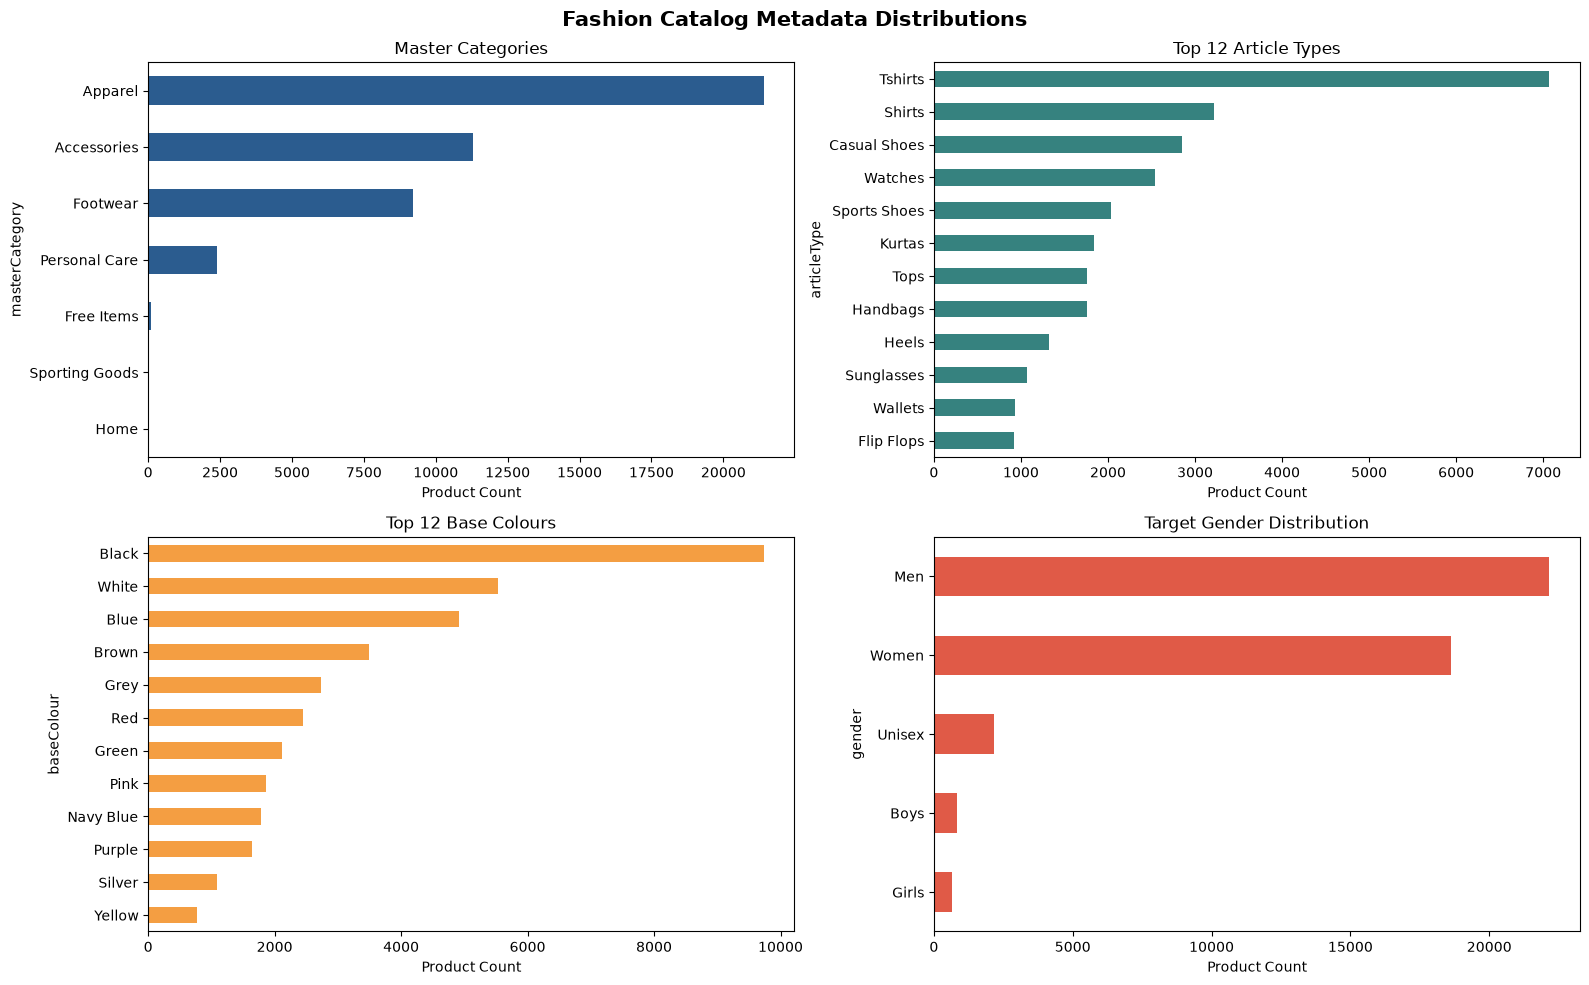

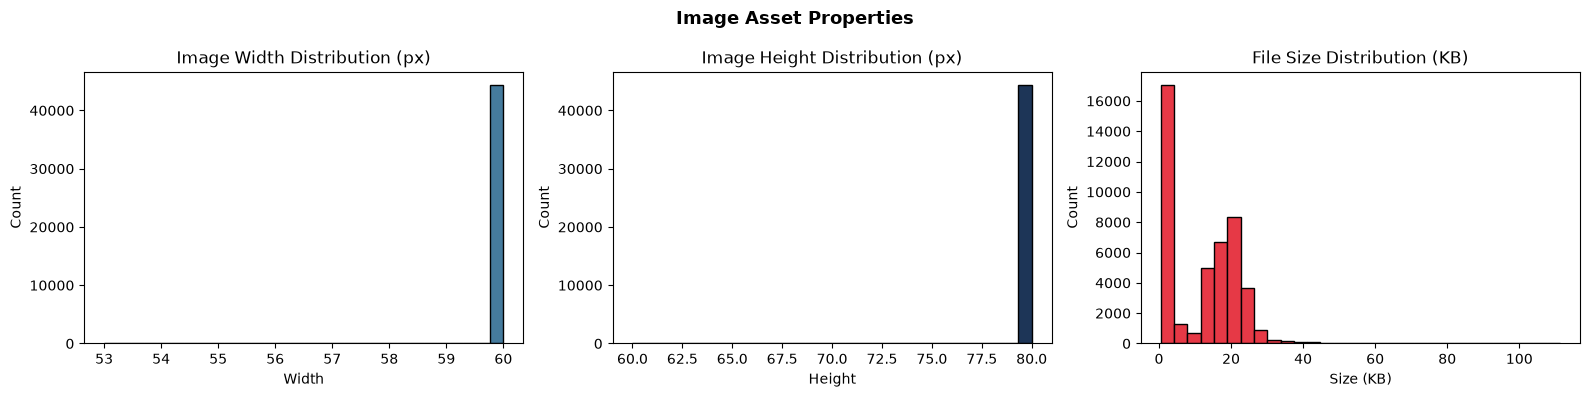

,width,height,aspect_ratio,file_size_kb
count,44441.000000,44441.000000,44441.000000,44441.000000
mean,59.998155,79.997367,0.750009,12.477041
std,0.112440,0.215337,0.003026,9.697157
min,53.000000,60.000000,0.662000,0.500000
25%,60.000000,80.000000,0.750000,2.200000
50%,60.000000,80.000000,0.750000,13.900000
75%,60.000000,80.000000,0.750000,19.900000
max,60.000000,80.000000,1.000000,111.300000


In [6]:
assert not catalog.empty, 'Catalog is empty. Check previous audit steps.'

# Plot 1: Category, Article Type, and Color Distributions
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

catalog['masterCategory'].value_counts().plot.barh(ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].set(title='Master Categories', xlabel='Product Count')
axes[0, 0].invert_yaxis()

catalog['articleType'].value_counts().head(12).plot.barh(ax=axes[0, 1], color='#36827f')
axes[0, 1].set(title='Top 12 Article Types', xlabel='Product Count')
axes[0, 1].invert_yaxis()

catalog['baseColour'].value_counts().head(12).plot.barh(ax=axes[1, 0], color='#f49e42')
axes[1, 0].set(title='Top 12 Base Colours', xlabel='Product Count')
axes[1, 0].invert_yaxis()

catalog['gender'].value_counts().plot.barh(ax=axes[1, 1], color='#e05a47')
axes[1, 1].set(title='Target Gender Distribution', xlabel='Product Count')
axes[1, 1].invert_yaxis()

fig.suptitle('Fashion Catalog Metadata Distributions', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'category_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Image Dimensions & File Sizes
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(catalog['width'], bins=30, color='#457b9d', edgecolor='black')
axes[0].set(title='Image Width Distribution (px)', xlabel='Width', ylabel='Count')

axes[1].hist(catalog['height'], bins=30, color='#1d3557', edgecolor='black')
axes[1].set(title='Image Height Distribution (px)', xlabel='Height', ylabel='Count')

axes[2].hist(catalog['file_size_kb'], bins=30, color='#e63946', edgecolor='black')
axes[2].set(title='File Size Distribution (KB)', xlabel='Size (KB)', ylabel='Count')

fig.suptitle('Image Asset Properties', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'image_properties.png', dpi=150, bbox_inches='tight')
plt.show()

display(catalog[['width', 'height', 'aspect_ratio', 'file_size_kb']].describe())

## 6. Reproducible Development Sample & Visual Gallery

We select a deterministic 500-product development sample (`catalog_sample_500.csv`) with `SEED = 42`.
This sample is ideal for rapid prototyping, sanity checking embedding models, and measuring batch encoding throughput before processing the full catalog.

We also verify orientation-corrected RGB image loading with `load_rgb(relative_path)` and preview random sample catalog items.

findfont: Failed to find font weight semibold, now using 700.


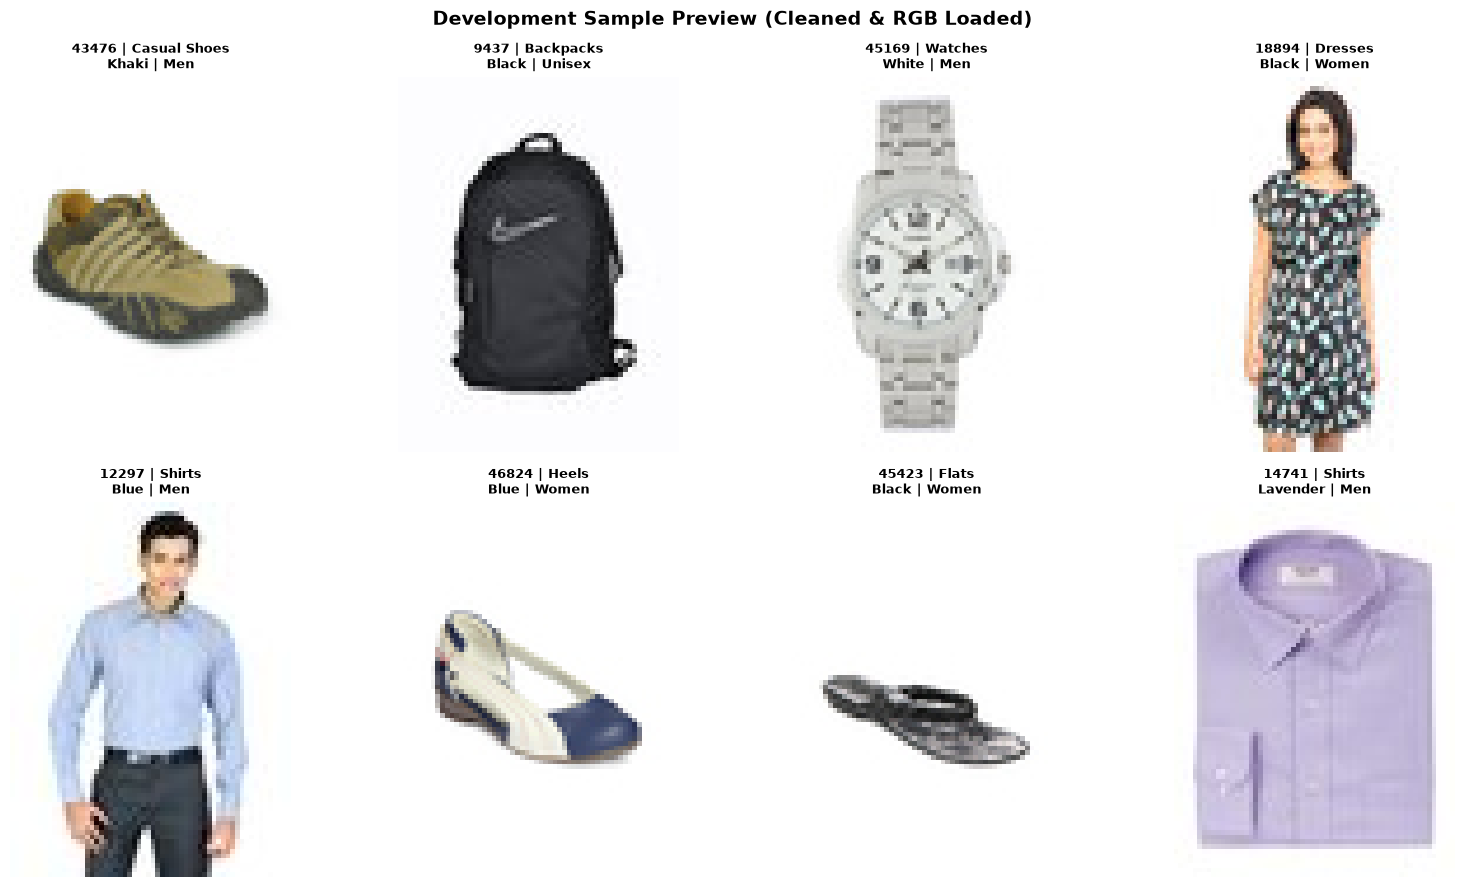

Development sample extracted: 500 items


In [7]:
def load_rgb(relative_path):
    with Image.open(ROOT / relative_path) as img:
        return ImageOps.exif_transpose(img).convert('RGB')

sample = catalog.sample(n=min(500, len(catalog)), random_state=SEED).sort_values('id').reset_index(drop=True)
preview = sample.sample(n=min(8, len(sample)), random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax in axes.flat:
    ax.axis('off')

for ax, (_, row) in zip(axes.flat, preview.iterrows()):
    im = load_rgb(row['image_path'])
    ax.imshow(im)
    title = f"{row['id']} | {row['articleType']}\n{row['baseColour']} | {row['gender']}"
    ax.set_title(title, fontsize=9, fontweight='semibold')

fig.suptitle('Development Sample Preview (Cleaned & RGB Loaded)', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'sample_gallery.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Development sample extracted: {len(sample):,} items')

## 7. Mathematical Integrity Verification and Artifact Export

We perform strict sanity assertions:
- Strict uniqueness of `id` in catalog.
- Zero missing values in primary metadata and image paths.
- Physical existence of all linked images on disk.
- Mathematical conservation of records across every cleaning and filtering stage:
  $$N_{\text{raw source}} = N_{\text{clean metadata}} + N_{\text{metadata exclusions}} + N_{\text{quarantined rows}}$$
  $$N_{\text{clean metadata}} = N_{\text{catalog}} + N_{\text{metadata without image}}$$

In [8]:
# Strict Data Assertions
assert catalog['id'].is_unique, 'Non-unique IDs detected in final catalog!'
assert catalog[['id', 'image_path', 'sha256', 'search_text']].notna().all().all(), 'Null values found in critical catalog fields!'
assert catalog[category_columns + ['productDisplayName']].notna().all().all(), 'Null values in category fields!'
assert catalog['width'].gt(0).all() and catalog['height'].gt(0).all(), 'Non-positive image dimensions detected!'
assert all((ROOT / path).is_file() for path in catalog['image_path']), 'Missing image files referenced in catalog!'

short_rows = int(csv_audit['action'].eq('quarantined_short_row').sum())
assert source_rows == len(raw) + short_rows, 'Conservation failure: raw records mismatch!'
assert len(raw) == len(clean) + len(metadata_exclusions), 'Conservation failure: clean metadata + exclusions mismatch!'
assert len(clean) == len(catalog) + len(metadata_without_image), 'Conservation failure: catalog + missing images mismatch!'
assert set(sample['id']).issubset(set(catalog['id'])), 'Sample IDs are not a subset of the catalog!'

# Export cleaned datasets and audit tables
tables = {
    'catalog_clean.csv': catalog,
    'catalog_sample_500.csv': sample,
    'metadata_clean.csv': clean,
    'csv_row_audit.csv': csv_audit,
    'metadata_exclusions.csv': metadata_exclusions,
    'invalid_years.csv': year_issues,
    'image_audit.csv': images,
    'ambiguous_images.csv': ambiguous_images,
    'images_without_metadata.csv': orphan_images,
    'metadata_without_usable_image.csv': metadata_without_image,
    'duplicate_image_groups.csv': duplicate_images,
    'ignored_files.csv': ignored_files,
    'missing_values_before_fill.csv': missing_before.rename_axis('column').reset_index(),
}

for filename, table in tables.items():
    table.to_csv(OUTPUT / filename, index=False, encoding='utf-8')
    print(f'Exported: {filename:<34} ({len(table):>6,} rows)')

# Generate comprehensive audit summary manifest
summary = {
    'source_csv': CSV_PATH.relative_to(ROOT).as_posix(),
    'source_csv_sha256': hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
    'source_records': source_rows,
    'repaired_csv_records': int(csv_audit['action'].eq('repaired_final_field').sum()),
    'quarantined_short_records': short_rows,
    'metadata_exclusions': {str(k): int(v) for k, v in metadata_exclusions['exclusion_reason'].value_counts().items()} if not metadata_exclusions.empty else {},
    'missing_metadata_before_fill': {str(k): int(v) for k, v in missing_before.items()},
    'invalid_years': len(year_issues),
    'image_files_scanned': len(images),
    'unreadable_images': int((~images['readable']).sum()),
    'images_with_invalid_filename_id': int(images['id'].isna().sum()),
    'ambiguous_image_ids': len(ambiguous_ids),
    'images_without_metadata': len(orphan_images),
    'metadata_without_usable_image': len(metadata_without_image),
    'clean_catalog_products': len(catalog),
    'products_sharing_image_bytes': len(duplicate_images),
    'development_sample_products': len(sample),
    'random_seed': SEED,
    'versions': {
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'pillow': PIL.__version__
    },
}

(OUTPUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('\nAudit summary saved to audit_summary.json.')
print('All integrity assertions passed successfully!')
display(pd.Series(summary, name='Audit Metrics').to_frame())

Exported: catalog_clean.csv                  (44,441 rows)
Exported: catalog_sample_500.csv             (   500 rows)


Exported: metadata_clean.csv                 (44,446 rows)
Exported: csv_row_audit.csv                  (    22 rows)
Exported: metadata_exclusions.csv            (     0 rows)
Exported: invalid_years.csv                  (     0 rows)
Exported: image_audit.csv                    (44,441 rows)
Exported: ambiguous_images.csv               (     0 rows)
Exported: images_without_metadata.csv        (     0 rows)
Exported: metadata_without_usable_image.csv  (     5 rows)
Exported: duplicate_image_groups.csv         ( 1,431 rows)
Exported: ignored_files.csv                  (     0 rows)
Exported: missing_values_before_fill.csv     (    10 rows)

Audit summary saved to audit_summary.json.
All integrity assertions passed successfully!


,Audit Metrics
source_csv,dataset/styles.csv
source_csv_sha256,cd86bd2d71b4065ed91786a52aa6ccc0eed343949791c6...
source_records,44446
repaired_csv_records,22
quarantined_short_records,0
metadata_exclusions,{}
missing_metadata_before_fill,"{'id': 0, 'gender': 0, 'masterCategory': 0, 's..."
invalid_years,0
image_files_scanned,44441
unreadable_images,0


## 8. Multi-Level Dimension Comparisons (Dataset Shapes, Image Resolutions & Model Tensors)

A critical requirement in multimodal data preparation is managing and comparing dimensions across three distinct levels:
1. **Dataset Dimensions ( \times D$):** How tabular dimensions, column semantics, missing values, and memory footprint evolve from the raw CSV through cleaning, filtering, and feature engineering.
2. **Native Image Dimensions ( \times H$):** Spatial resolution and aspect ratio variations across fashion categories in the physical image files.
3. **Deep Learning Input Dimensions ( \times H \times W$):** How the small native thumbnails ( \times 80$) map into the standardized input tensor format ( \times 224 \times 224$) expected by vision-language models like CLIP ViT-B/32.
4. **Representation Compression:** The dimensionality reduction from 150,528 raw pixel values to a compact 512-dimensional semantic latent embedding.

,Pipeline Stage,Rows (N),Columns (D),Row Retention (%),Total Data Cells,Missing Cells,Missing Rate (%),Memory (MB)
0,1. Raw Source CSV,44446,11,100.0%,488906,23,0.005%,24.820
1,2. Cleaned Metadata,44446,19,100.0%,844474,1,0.000%,21.690
2,3. Excluded (No Usable Image),5,20,0.01%,100,0,0.000%,0.003
3,4. Final Clean Multimodal Catalog,44441,29,99.99%,1288789,1,0.000%,43.850
4,5. Development Sample,500,29,1.12%,14500,0,0.000%,0.490


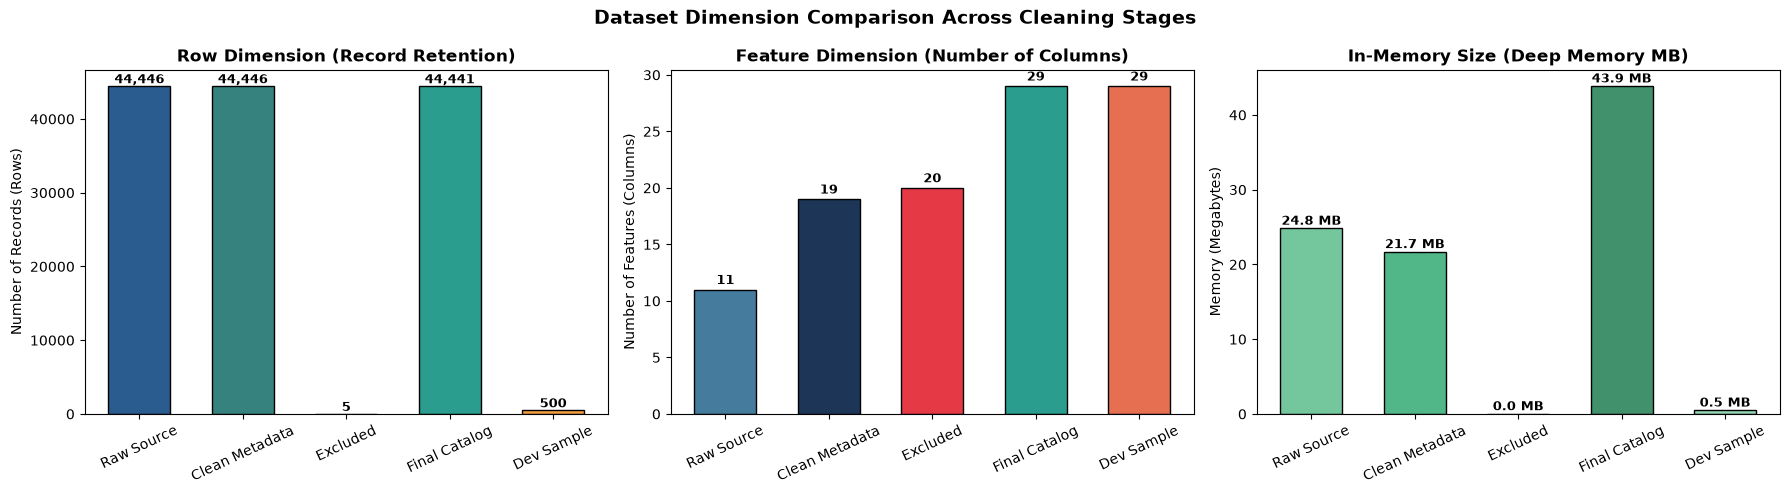

In [9]:
# 8.1 Dataset Dimensions Across Data Cleaning Stages

raw_mem = raw.memory_usage(deep=True).sum() / (1024 * 1024)
clean_mem = clean.memory_usage(deep=True).sum() / (1024 * 1024)
missing_mem = metadata_without_image.memory_usage(deep=True).sum() / (1024 * 1024)
catalog_mem = catalog.memory_usage(deep=True).sum() / (1024 * 1024)
sample_mem = sample.memory_usage(deep=True).sum() / (1024 * 1024)

dim_comparison_data = [
    {
        'Pipeline Stage': '1. Raw Source CSV',
        'Rows (N)': len(raw),
        'Columns (D)': len(raw.columns),
        'Row Retention (%)': f'{(len(raw)/len(raw))*100:.1f}%',
        'Total Data Cells': len(raw) * len(raw.columns),
        'Missing Cells': int(missing_before.sum()),
        'Missing Rate (%)': f'{(missing_before.sum() / (len(raw) * len(raw.columns))) * 100:.3f}%',
        'Memory (MB)': round(raw_mem, 2)
    },
    {
        'Pipeline Stage': '2. Cleaned Metadata',
        'Rows (N)': len(clean),
        'Columns (D)': len(clean.columns),
        'Row Retention (%)': f'{(len(clean)/len(raw))*100:.1f}%',
        'Total Data Cells': len(clean) * len(clean.columns),
        'Missing Cells': int(clean.isna().sum().sum()),
        'Missing Rate (%)': '0.000%',
        'Memory (MB)': round(clean_mem, 2)
    },
    {
        'Pipeline Stage': '3. Excluded (No Usable Image)',
        'Rows (N)': len(metadata_without_image),
        'Columns (D)': len(metadata_without_image.columns),
        'Row Retention (%)': f'{(len(metadata_without_image)/len(raw))*100:.2f}%',
        'Total Data Cells': len(metadata_without_image) * len(metadata_without_image.columns),
        'Missing Cells': int(metadata_without_image.isna().sum().sum()),
        'Missing Rate (%)': '0.000%',
        'Memory (MB)': round(missing_mem, 3)
    },
    {
        'Pipeline Stage': '4. Final Clean Multimodal Catalog',
        'Rows (N)': len(catalog),
        'Columns (D)': len(catalog.columns),
        'Row Retention (%)': f'{(len(catalog)/len(raw))*100:.2f}%',
        'Total Data Cells': len(catalog) * len(catalog.columns),
        'Missing Cells': int(catalog.isna().sum().sum()),
        'Missing Rate (%)': '0.000%',
        'Memory (MB)': round(catalog_mem, 2)
    },
    {
        'Pipeline Stage': '5. Development Sample',
        'Rows (N)': len(sample),
        'Columns (D)': len(sample.columns),
        'Row Retention (%)': f'{(len(sample)/len(raw))*100:.2f}%',
        'Total Data Cells': len(sample) * len(sample.columns),
        'Missing Cells': int(sample.isna().sum().sum()),
        'Missing Rate (%)': '0.000%',
        'Memory (MB)': round(sample_mem, 2)
    },
]

df_dim_comparison = pd.DataFrame(dim_comparison_data)
display(df_dim_comparison)

# Visualization of Dataset Dimensions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
stages_short = ['Raw Source', 'Clean Metadata', 'Excluded', 'Final Catalog', 'Dev Sample']

# 1. Row Dimension Funnel
colors_rows = ['#2b5c8f', '#36827f', '#e05a47', '#2a9d8f', '#f49e42']
bars1 = axes[0].bar(stages_short, df_dim_comparison['Rows (N)'], color=colors_rows, edgecolor='black', width=0.6)
axes[0].set_title('Row Dimension (Record Retention)', fontweight='bold')
axes[0].set_ylabel('Number of Records (Rows)')
axes[0].tick_params(axis='x', rotation=25)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 400, f'{h:,}', ha='center', fontsize=9, fontweight='bold')

# 2. Feature / Column Dimension Expansion
colors_cols = ['#457b9d', '#1d3557', '#e63946', '#2a9d8f', '#e76f51']
bars2 = axes[1].bar(stages_short, df_dim_comparison['Columns (D)'], color=colors_cols, edgecolor='black', width=0.6)
axes[1].set_title('Feature Dimension (Number of Columns)', fontweight='bold')
axes[1].set_ylabel('Number of Features (Columns)')
axes[1].tick_params(axis='x', rotation=25)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 0.5, f'{h}', ha='center', fontsize=9, fontweight='bold')

# 3. Memory Footprint Dimension
colors_mem = ['#74c69d', '#52b788', '#d90429', '#40916c', '#95d5b2']
bars3 = axes[2].bar(stages_short, df_dim_comparison['Memory (MB)'], color=colors_mem, edgecolor='black', width=0.6)
axes[2].set_title('In-Memory Size (Deep Memory MB)', fontweight='bold')
axes[2].set_ylabel('Memory (Megabytes)')
axes[2].tick_params(axis='x', rotation=25)
for bar in bars3:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2, h + 0.5, f'{h:.1f} MB', ha='center', fontsize=9, fontweight='bold')

fig.suptitle('Dataset Dimension Comparison Across Cleaning Stages', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'dimension_comparison_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

Image Resolution Frequency Table:


,resolution,width,height,aspect_ratio,image_count,percentage
0,60 x 80,60,80,0.750,44418,99.95
1,53 x 80,53,80,0.662,10,0.02
2,60 x 60,60,60,1.000,5,0.01
3,54 x 80,54,80,0.675,2,0.00
4,60 x 79,60,79,0.759,2,0.00
5,60 x 77,60,77,0.779,2,0.00
6,60 x 75,60,75,0.800,1,0.00
7,60 x 76,60,76,0.789,1,0.00


Non-standard dimension images: 23 out of 44,441 (0.05%)


,id,productDisplayName,masterCategory,articleType,width,height,aspect_ratio
154,1799,Domyos Men Blue & White Tracksuit,Apparel,Track Pants,60,60,1.000
155,1800,Quechua Unisex Black Solid Backpack,Accessories,Backpacks,60,60,1.000
156,1801,Quechua Women 10L Pink Bag,Accessories,Backpacks,60,60,1.000
563,2311,Nike Womens Pink T-shirt,Apparel,Tshirts,60,60,1.000
3167,5408,Quechua Wayta Jr Blue,Footwear,Sports Shoes,60,60,1.000
8039,11151,Indigo Nation Men Check Grey Ties,Accessories,Ties,60,77,0.779
8048,11160,Indigo Nation Men Check Grey Ties,Accessories,Ties,60,77,0.779
11116,14776,Arrow Men Stripes Blue Shirts,Apparel,Shirts,60,76,0.789


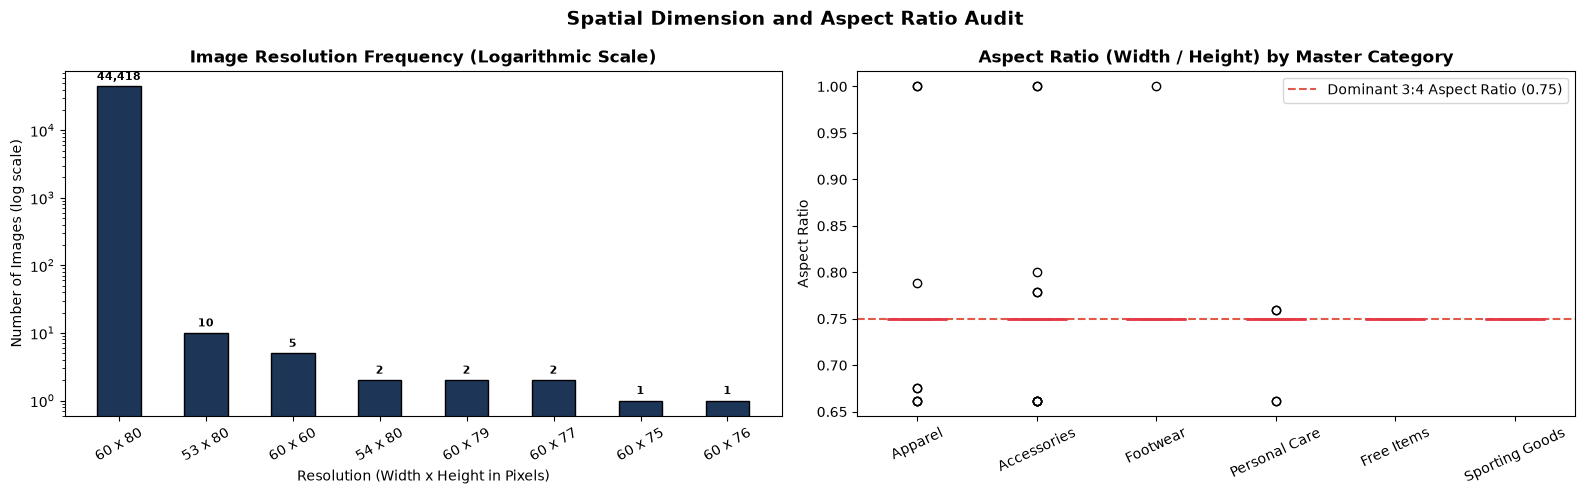

In [10]:
# 8.2 Image Spatial Dimensions and Aspect Ratio Comparison

dim_counts = catalog.groupby(['width', 'height']).size().reset_index(name='image_count')
dim_counts['percentage'] = ((dim_counts['image_count'] / len(catalog)) * 100).round(2)
dim_counts['aspect_ratio'] = (dim_counts['width'] / dim_counts['height']).round(3)
dim_counts['resolution'] = dim_counts['width'].astype(str) + ' x ' + dim_counts['height'].astype(str)
dim_counts = dim_counts.sort_values('image_count', ascending=False).reset_index(drop=True)

print('Image Resolution Frequency Table:')
display(dim_counts[['resolution', 'width', 'height', 'aspect_ratio', 'image_count', 'percentage']])

# Inspect non-standard dimension items
non_standard_dim = catalog[~((catalog['width'] == 60) & (catalog['height'] == 80))]
print(f'Non-standard dimension images: {len(non_standard_dim)} out of {len(catalog):,} ({len(non_standard_dim)/len(catalog)*100:.2f}%)')
if not non_standard_dim.empty:
    display(non_standard_dim[['id', 'productDisplayName', 'masterCategory', 'articleType', 'width', 'height', 'aspect_ratio']].head(8))

# Visualizing Image Resolution Frequencies & Aspect Ratios Across Categories
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Resolution frequency distribution (log scale)
bars = axes[0].bar(dim_counts['resolution'], dim_counts['image_count'], color='#1d3557', edgecolor='black', width=0.5)
axes[0].set_yscale('log')
axes[0].set_title('Image Resolution Frequency (Logarithmic Scale)', fontweight='bold')
axes[0].set_xlabel('Resolution (Width x Height in Pixels)')
axes[0].set_ylabel('Number of Images (log scale)')
axes[0].tick_params(axis='x', rotation=30)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h * 1.25, f'{h:,}', ha='center', fontsize=8, fontweight='bold')

# Subplot 2: Category-wise Aspect Ratio comparison
major_cats = catalog['masterCategory'].value_counts()
major_cats = major_cats[major_cats >= 20].index
aspect_data = [catalog.loc[catalog['masterCategory'] == c, 'aspect_ratio'].dropna() for c in major_cats]

bp = axes[1].boxplot(aspect_data, tick_labels=major_cats, patch_artist=True,
                     boxprops=dict(facecolor='#457b9d', color='black'),
                     medianprops=dict(color='#e63946', linewidth=2))
axes[1].axhline(0.75, color='#e05a47', linestyle='--', linewidth=1.5, label='Dominant 3:4 Aspect Ratio (0.75)')
axes[1].set_title('Aspect Ratio (Width / Height) by Master Category', fontweight='bold')
axes[1].set_ylabel('Aspect Ratio')
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend(loc='upper right')

fig.suptitle('Spatial Dimension and Aspect Ratio Audit', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'dimension_comparison_images.png', dpi=150, bbox_inches='tight')
plt.show()

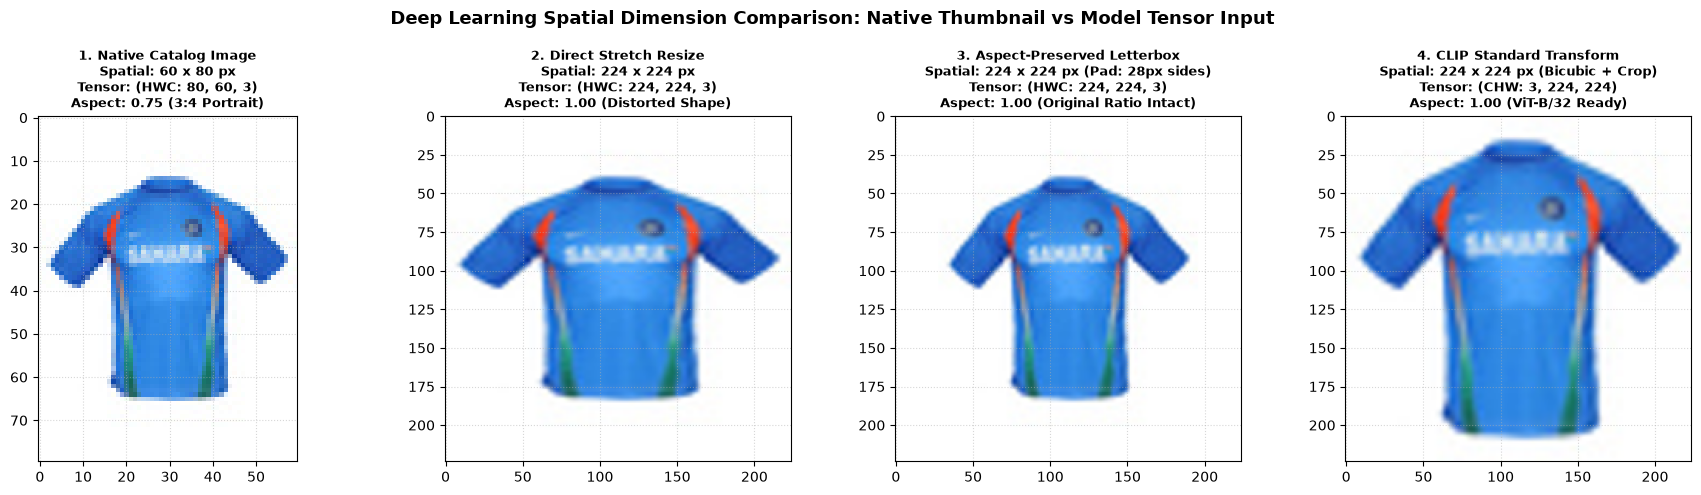

Multimodal Pipeline Dimensionality Progression:


,Level,Spatial Dimensions,Channels / Depth,Total Elements,Semantic Representation
0,1. Raw Image Asset,60 x 80,3 (RGB uint8),"14,400 bytes",Uncompressed raw pixel raster
1,2. CLIP Input Tensor,224 x 224,3 (Float32 normalized),"150,528 floats (602 KB)","49 vision patches (ViT-B/32, 32x32 patch)"
2,3. Text Representation,1D Sequence,77 Tokens (Context Window),77 integer token IDs,Byte-pair encoded search text string
3,4. CLIP Latent Embedding,1D Vector,512 Dimensions (Float32),512 floats (2 KB),L2-normalized shared semantic multimodal vector


In [11]:
# 8.3 Deep Learning Input Dimension Comparison: Native Image vs CLIP Model Tensor

# Pick a representative sample image
sample_row = catalog.iloc[0]
img_path = ROOT / sample_row['image_path']

with Image.open(img_path) as im:
    orig_img = ImageOps.exif_transpose(im).convert('RGB')

orig_w, orig_h = orig_img.size

# Transformation 1: Direct stretched resize to 224x224
direct_stretched = orig_img.resize((224, 224), Image.Resampling.BICUBIC)

# Transformation 2: Aspect-ratio preserved padding (Letterbox) to 224x224
scale = 224 / max(orig_w, orig_h)
pad_w, pad_h = int(orig_w * scale), int(orig_h * scale)
scaled_temp = orig_img.resize((pad_w, pad_h), Image.Resampling.BICUBIC)
letterbox_img = Image.new('RGB', (224, 224), (255, 255, 255))
offset_x, offset_y = (224 - pad_w) // 2, (224 - pad_h) // 2
letterbox_img.paste(scaled_temp, (offset_x, offset_y))

# Transformation 3: Standard CLIP Preprocessing (Resize min edge to 224 + Center Crop 224x224)
scale_clip = 224 / min(orig_w, orig_h)
clip_w, clip_h = int(round(orig_w * scale_clip)), int(round(orig_h * scale_clip))
scaled_clip = orig_img.resize((clip_w, clip_h), Image.Resampling.BICUBIC)
crop_x = (clip_w - 224) // 2
crop_y = (clip_h - 224) // 2
clip_center_crop = scaled_clip.crop((crop_x, crop_y, crop_x + 224, crop_y + 224))

# Visual Side-by-Side Comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(orig_img)
axes[0].set_title(f'1. Native Catalog Image\nSpatial: {orig_w} x {orig_h} px\nTensor: (HWC: 80, 60, 3)\nAspect: {orig_w/orig_h:.2f} (3:4 Portrait)', fontsize=9.5, fontweight='bold')

axes[1].imshow(direct_stretched)
axes[1].set_title('2. Direct Stretch Resize\nSpatial: 224 x 224 px\nTensor: (HWC: 224, 224, 3)\nAspect: 1.00 (Distorted Shape)', fontsize=9.5, fontweight='bold')

axes[2].imshow(letterbox_img)
axes[2].set_title(f'3. Aspect-Preserved Letterbox\nSpatial: 224 x 224 px (Pad: {offset_x}px sides)\nTensor: (HWC: 224, 224, 3)\nAspect: 1.00 (Original Ratio Intact)', fontsize=9.5, fontweight='bold')

axes[3].imshow(clip_center_crop)
axes[3].set_title('4. CLIP Standard Transform\nSpatial: 224 x 224 px (Bicubic + Crop)\nTensor: (CHW: 3, 224, 224)\nAspect: 1.00 (ViT-B/32 Ready)', fontsize=9.5, fontweight='bold')

for ax in axes:
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
    ax.grid(True, linestyle=':', alpha=0.5)

fig.suptitle('Deep Learning Spatial Dimension Comparison: Native Thumbnail vs Model Tensor Input', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'dimension_comparison_clip_input.png', dpi=150, bbox_inches='tight')
plt.show()

# Dimension Comparison Across Multimodal Pipeline Levels
pipeline_dimensions = pd.DataFrame([
    {
        'Level': '1. Raw Image Asset',
        'Spatial Dimensions': f'{orig_w} x {orig_h}',
        'Channels / Depth': '3 (RGB uint8)',
        'Total Elements': f'{orig_w * orig_h * 3:,} bytes',
        'Semantic Representation': 'Uncompressed raw pixel raster'
    },
    {
        'Level': '2. CLIP Input Tensor',
        'Spatial Dimensions': '224 x 224',
        'Channels / Depth': '3 (Float32 normalized)',
        'Total Elements': f'{224 * 224 * 3:,} floats (602 KB)',
        'Semantic Representation': '49 vision patches (ViT-B/32, 32x32 patch)'
    },
    {
        'Level': '3. Text Representation',
        'Spatial Dimensions': '1D Sequence',
        'Channels / Depth': '77 Tokens (Context Window)',
        'Total Elements': '77 integer token IDs',
        'Semantic Representation': 'Byte-pair encoded search text string'
    },
    {
        'Level': '4. CLIP Latent Embedding',
        'Spatial Dimensions': '1D Vector',
        'Channels / Depth': '512 Dimensions (Float32)',
        'Total Elements': '512 floats (2 KB)',
        'Semantic Representation': 'L2-normalized shared semantic multimodal vector'
    },
])

print('Multimodal Pipeline Dimensionality Progression:')
display(pipeline_dimensions)

In [12]:
# 8.4 Export Dimension Comparison Artifacts
df_dim_comparison.to_csv(OUTPUT / 'dataset_dimension_comparison.csv', index=False)
dim_counts.to_csv(OUTPUT / 'image_dimension_frequencies.csv', index=False)
pipeline_dimensions.to_csv(OUTPUT / 'pipeline_dimension_progression.csv', index=False)

print('Dimension comparison artifacts exported to:')
print('  -', OUTPUT / 'dataset_dimension_comparison.csv')
print('  -', OUTPUT / 'image_dimension_frequencies.csv')
print('  -', OUTPUT / 'pipeline_dimension_progression.csv')
print('  -', OUTPUT / 'dimension_comparison_dataset.png')
print('  -', OUTPUT / 'dimension_comparison_images.png')
print('  -', OUTPUT / 'dimension_comparison_clip_input.png')

Dimension comparison artifacts exported to:
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\dataset_dimension_comparison.csv
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\image_dimension_frequencies.csv
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\pipeline_dimension_progression.csv
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\dimension_comparison_dataset.png
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\dimension_comparison_images.png
  - D:\data science and analysis\data analysis with python\deep learning\week3\artifacts\data_preparation\dimension_comparison_clip_input.png


## Summary of Generated Artifacts

The following files are now saved in rtifacts/data_preparation/:
- **catalog_clean.csv**: Full cleaned dataset of 44,441 verified products with valid IDs, cleaned metadata, relative image paths, SHA-256 hashes, image dimensions, and combined search_text. Ready for CLIP encoding.
- **catalog_sample_500.csv**: Deterministic sample of 500 items for rapid experimentation and model benchmarking.
- **metadata_clean.csv**: Standardized metadata for all 44,446 source records.
- **udit_summary.json**: Complete machine-readable audit report with data provenance hashes, counts, and environment details.
- **Dimension Artifacts**:
  - dataset_dimension_comparison.csv: Tabular shape, row retention, and memory metrics across all stages.
  - image_dimension_frequencies.csv: Image resolution counts, percentages, and aspect ratios.
  - pipeline_dimension_progression.csv: Multi-level progression from raw pixel raster to 512-dim embedding.
  - dimension_comparison_dataset.png, dimension_comparison_images.png, dimension_comparison_clip_input.png: Visualization figures.
- **Audit CSVs**: Detailed logs of CSV row repairs, missing image exclusions, and duplicate image groups.
- **category_coverage.png**, **image_properties.png**, **sample_gallery.png**: High-resolution visualization figures.